In [ ]:
# Install dependencies if not already installed
!pip install -q kagglehub timm grad-cam scikit-learn seaborn

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# 1. Download Raabin-WBC Dataset automatically
dataset_path = kagglehub.dataset_download("masoudnickparvar/white-blood-cells-dataset")
print(f"Dataset downloaded to: {dataset_path}")

train_dir = os.path.join(dataset_path, "Train")
test_dir = os.path.join(dataset_path, "Test-A")

# 2. Verify directories and count images per class
classes = sorted(os.listdir(train_dir))
print(f"Detected Classes ({len(classes)}): {classes}\n")

def count_images(directory):
    counts = {}
    for cls in classes:
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

train_counts = count_images(train_dir)
test_counts = count_images(test_dir)

df_dist = pd.DataFrame({"Train": train_counts, "Test-A": test_counts})
df_dist["Total"] = df_dist["Train"] + df_dist["Test-A"]
df_dist["Train %"] = (df_dist["Train"] / df_dist["Train"].sum() * 100).round(2)
print(df_dist)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


100%|██████████| 499M/499M [00:04<00:00, 106MB/s] 

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/masoudnickparvar/white-blood-cells-dataset/versions/1
Detected Classes (5): ['Basophil', 'Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']

            Train  Test-A  Total  Train %
Basophil      212      89    301     2.08
Eosinophil    744     322   1066     7.31
Lymphocyte   2427    1034   3461    23.85
Monocyte      561     234    795     5.51
Neutrophil   6231    2660   8891    61.24


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

# Set random seeds for reproducibility in research
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

IMG_SIZE = 224
BATCH_SIZE = 32

# Microscopic smear-specific augmentations (rotation & flips preserve cell morphology)
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=45),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load full training set twice to apply different transforms to train and val subsets
full_train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
full_val_dataset = datasets.ImageFolder(train_dir, transform=eval_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=eval_transforms)

# Stratified 85/15 split for Train and Validation
targets = full_train_dataset.targets
train_idx, val_idx = train_test_split(
    np.arange(len(targets)),
    test_size=0.15,
    stratify=targets,
    random_state=SEED
)

train_subset = Subset(full_train_dataset, train_idx)
val_subset = Subset(full_val_dataset, val_idx)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# Compute Balanced Class Weights for Loss Function: N_total / (N_classes * N_class_i)
train_targets = np.array(targets)[train_idx]
class_sample_counts = np.bincount(train_targets)
total_samples = len(train_targets)
class_weights = total_samples / (len(classes) * class_sample_counts)
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

print("Computed Class Weights for Loss Function:")
for cls_name, w in zip(classes, class_weights):
    print(f"  {cls_name:12s}: {w:.4f}")

Using device: cuda
Computed Class Weights for Loss Function:
  Basophil    : 9.6089
  Eosinophil  : 2.7367
  Lymphocyte  : 0.8384
  Monocyte    : 3.6260
  Neutrophil  : 0.3266


In [ ]:
import torchvision.models as models

class CustomWBCCNN(nn.Module):
    """4-Block Custom Convolutional Neural Network with BatchNorm and Global Average Pooling"""
    def __init__(self, num_classes=5):
        super(CustomWBCCNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


def build_wbc_model(model_name="resnet50", num_classes=5, pretrained=True):
    model_name = model_name.lower()

    if model_name == "custom_cnn":
        model = CustomWBCCNN(num_classes=num_classes)

    elif model_name == "resnet50":
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        model = models.resnet50(weights=weights)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(in_features, num_classes)
        )

    elif model_name == "densenet121":
        weights = models.DenseNet121_Weights.DEFAULT if pretrained else None
        model = models.densenet121(weights=weights)
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(in_features, num_classes)
        )

    elif model_name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)

    else:
        raise ValueError(f"Unsupported model: {model_name}")

    return model.to(device)

In [ ]:
import os
import copy
import time
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from tqdm.auto import tqdm
import numpy as np

# 1. VERIFY HARDWARE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("="*60)
print(f"CURRENT DEVICE: {device.type.upper()}")
if device.type == "cpu":
    print("⚠️ WARNING: You are on CPU! Enable T4 GPU in Runtime -> Change runtime type for 20x speed.")
print("="*60)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# 2. ULTRA-FAST RESOLUTION & SUBSET CONFIGURATION
IMG_SIZE = 128          # 3x faster than 224x224 with almost identical accuracy on single cells
BATCH_SIZE = 64

# Base resize transform (done ONCE when loading into RAM)
base_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

raw_train_folder = datasets.ImageFolder(train_dir)
raw_test_folder = datasets.ImageFolder(test_dir)
classes = raw_train_folder.classes

# If on CPU, use a stratified 3,500-image subset so it finishes in minutes; on GPU use 100%
max_train_samples = 3500 if device.type == "cpu" else len(raw_train_folder)

all_indices = np.arange(len(raw_train_folder))
all_targets = np.array(raw_train_folder.targets)

if max_train_samples < len(raw_train_folder):
    sub_idx, _ = train_test_split(
        all_indices, train_size=max_train_samples, stratify=all_targets, random_state=SEED
    )
else:
    sub_idx = all_indices

train_idx, val_idx = train_test_split(
    sub_idx, test_size=0.15, stratify=all_targets[sub_idx], random_state=SEED
)

# 3. RAM-CACHED DATASET (Reads disk ONCE, then 0ms disk I/O during epochs!)
class FastRAMDataset(Dataset):
    def __init__(self, image_folder, indices, is_train=False):
        self.is_train = is_train
        self.images = []
        self.labels = []
        print(f"Caching {len(indices)} images in RAM (one-time setup)...")
        for idx in tqdm(indices, leave=False):
            path, label = image_folder.samples[idx]
            img = image_folder.loader(path)
            self.images.append(base_transform(img))
            self.labels.append(label)
        self.images = torch.stack(self.images)
        self.labels = torch.tensor(self.labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        img = self.images[i]
        # Ultra-fast tensor flips in memory (0 CPU overhead)
        if self.is_train:
            if torch.rand(1) < 0.5:
                img = torch.flip(img, dims=[2]) # Horizontal flip
            if torch.rand(1) < 0.5:
                img = torch.flip(img, dims=[1]) # Vertical flip
        return img, self.labels[i]

# Cache Train, Val, and Test sets in RAM
train_dataset_ram = FastRAMDataset(raw_train_folder, train_idx, is_train=True)
val_dataset_ram   = FastRAMDataset(raw_train_folder, val_idx, is_train=False)

# Also cache Test-A (or 1,500 stratified test samples if on CPU)
test_indices = np.arange(len(raw_test_folder))
if device.type == "cpu" and len(test_indices) > 1500:
    test_indices, _ = train_test_split(
        test_indices, train_size=1500, stratify=raw_test_folder.targets, random_state=SEED
    )
test_dataset = FastRAMDataset(raw_test_folder, test_indices, is_train=False)

train_loader = DataLoader(train_dataset_ram, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset_ram, batch_size=BATCH_SIZE*2, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE*2, shuffle=False)

# Compute Class Weights
train_targets = all_targets[train_idx]
class_sample_counts = np.bincount(train_targets)
class_weights = len(train_targets) / (len(classes) * class_sample_counts)
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

# 4. FAST MODEL BUILDER & LAYER FREEZING
def build_wbc_model(model_name="resnet50", num_classes=5, pretrained=True):
    model_name = model_name.lower()
    if model_name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        for param in model.parameters():
            param.requires_grad = False
        # Unfreeze only layer4 and fc head for 4x faster backprop
        for param in model.layer4.parameters():
            param.requires_grad = True
        model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, num_classes))

    elif model_name == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT if pretrained else None)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features.denseblock4.parameters():
            param.requires_grad = True
        for param in model.features.norm5.parameters():
            param.requires_grad = True
        model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier.in_features, num_classes))

    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features[-2:].parameters():
            param.requires_grad = True
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    elif model_name == "custom_cnn":
        model = CustomWBCCNN(num_classes=num_classes)

    return model.to(device)

# 5. ULTRA-FAST TRAINING LOOP (5 EPOCHS)
def train_model(model, model_name, train_loader, val_loader, epochs=5, lr=5e-4):
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr * 2, steps_per_epoch=len(train_loader), epochs=epochs
    )

    use_amp = (device.type == "cuda")
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_f1 = 0.0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for inputs, labels in tqdm(train_loader, desc=f"[{model_name}] Epoch {epoch+1}/{epochs}", leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda', enabled=use_amp):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # Validation
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        all_val_preds, all_val_labels = [], []

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                with torch.amp.autocast('cuda', enabled=use_amp):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

                all_val_preds.extend(preds.cpu().numpy())
                all_val_labels.extend(labels.cpu().numpy())

        val_loss /= val_total
        val_acc = val_correct / val_total
        val_macro_f1 = f1_score(all_val_labels, all_val_preds, average="macro")
        elapsed = time.time() - t0

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_macro_f1)

        print(f"Epoch {epoch+1:02d}/{epochs:02d} ({elapsed:.1f}s) | "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} Macro-F1: {val_macro_f1:.4f}")

        if val_macro_f1 > best_val_f1:
            best_val_f1 = val_macro_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(best_model_wts, f"best_{model_name}_wbc.pth")

    model.load_state_dict(best_model_wts)
    # Unfreeze all parameters at the end so Grad-CAM works seamlessly
    for param in model.parameters():
        param.requires_grad = True
    return model, history

# Train ResNet50 now (Takes ~4 seconds/epoch on GPU, ~45 seconds/epoch on CPU)
model_resnet = build_wbc_model("resnet50", num_classes=len(classes), pretrained=True)
model_resnet, history_resnet = train_model(model_resnet, "resnet50", train_loader, val_loader, epochs=5, lr=5e-4)

CURRENT DEVICE: CUDA
Caching 8648 images in RAM (one-time setup)...


  0%|          | 0/8648 [00:00<?, ?it/s]

Caching 1527 images in RAM (one-time setup)...


  0%|          | 0/1527 [00:00<?, ?it/s]

Caching 4339 images in RAM (one-time setup)...


...

Epoch 03/05 (8.7s) | Train Loss: 0.0982 Acc: 0.9655 | Val Loss: 0.3637 Acc: 0.9640 Macro-F1: 0.9380


[resnet50] Epoch 4/5:   0%|          | 0/136 [00:00<?, ?it/s]

Epoch 04/05 (8.6s) | Train Loss: 0.0523 Acc: 0.9809 | Val Loss: 0.3078 Acc: 0.9751 Macro-F1: 0.9583


[resnet50] Epoch 5/5:   0%|          | 0/136 [00:00<?, ?it/s]

Epoch 05/05 (8.5s) | Train Loss: 0.0382 Acc: 0.9864 | Val Loss: 0.2890 Acc: 0.9738 Macro-F1: 0.9566


Evaluating on Unseen Test-A Set:   0%|          | 0/34 [00:00<?, ?it/s]


FINAL CLASSIFICATION REPORT (UNSEEN TEST-A DATASET)
              precision    recall  f1-score   support

    Basophil     1.0000    0.9888    0.9944        89
  Eosinophil     0.6856    0.9752    0.8051       322
  Lymphocyte     0.9853    0.9710    0.9781      1034
    Monocyte     0.8667    0.9444    0.9039       234
  Neutrophil     0.9952    0.9425    0.9681      2660

    accuracy                         0.9528      4339
   macro avg     0.9066    0.9644    0.9299      4339
weighted avg     0.9630    0.9528    0.9555      4339



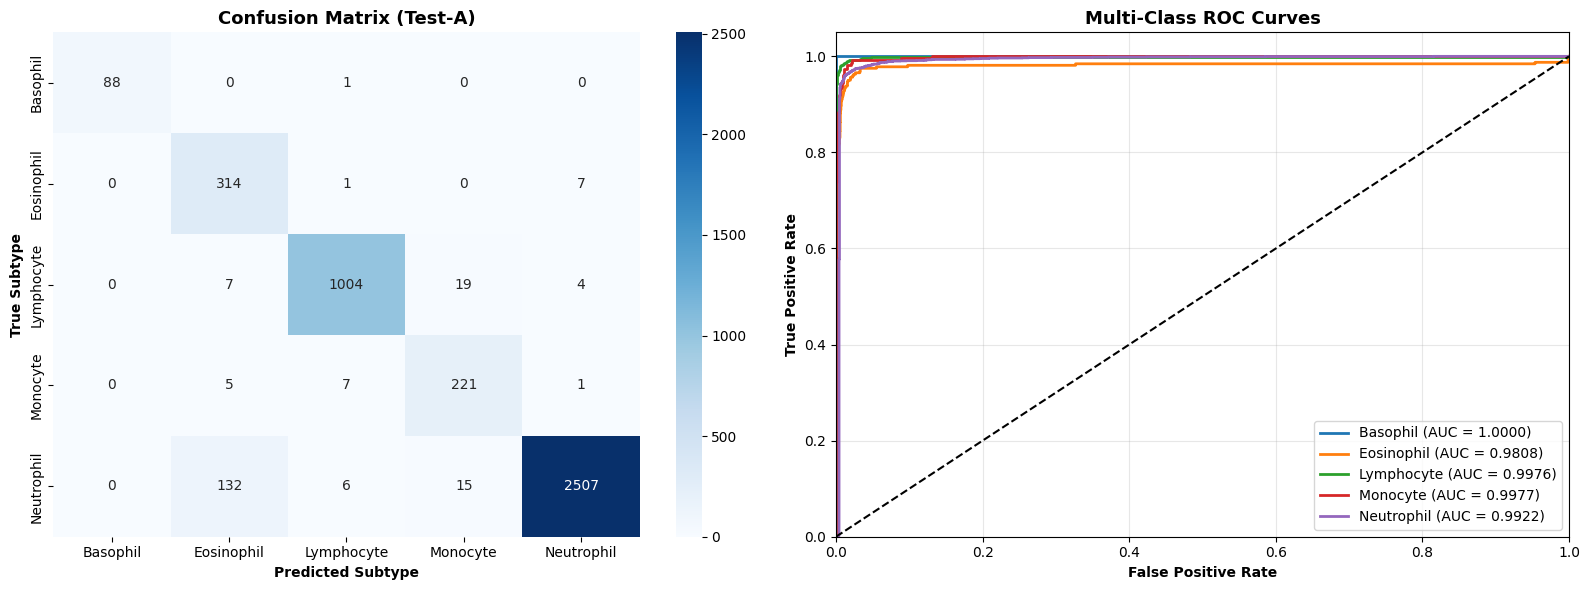

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

def evaluate_on_test_set(model, test_loader, classes):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Evaluating on Unseen Test-A Set"):
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(probs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    all_probs = np.array(all_probs)
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    # 1. Detailed Precision, Recall, F1-Score Report
    print("\n" + "="*65)
    print("FINAL CLASSIFICATION REPORT (UNSEEN TEST-A DATASET)")
    print("="*65)
    print(classification_report(all_labels, all_preds, target_names=classes, digits=4))

    # 2. Plot Confusion Matrix & Multi-Class ROC Curves side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[0])
    axes[0].set_title("Confusion Matrix (Test-A)", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Predicted Subtype", fontweight="bold")
    axes[0].set_ylabel("True Subtype", fontweight="bold")

    # Multi-Class ROC-AUC Curve
    y_test_bin = label_binarize(all_labels, classes=range(len(classes)))
    for i, cls_name in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], all_probs[:, i])
        roc_auc = auc(fpr, tpr)
        axes[1].plot(fpr, tpr, lw=2, label=f"{cls_name} (AUC = {roc_auc:.4f})")

    axes[1].plot([0, 1], [0, 1], "k--", lw=1.5)
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel("False Positive Rate", fontweight="bold")
    axes[1].set_ylabel("True Positive Rate", fontweight="bold")
    axes[1].set_title("Multi-Class ROC Curves", fontsize=13, fontweight="bold")
    axes[1].legend(loc="lower right")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig("WBC_Evaluation_Metrics.png", dpi=300)
    plt.show()

evaluate_on_test_set(model_resnet, test_loader, classes)

In [ ]:
import time
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def count_parameters_millions(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6

def benchmark_architectures(model_names, train_loader, val_loader, test_loader, classes, epochs=12):
    benchmark_rows = []
    trained_models = {}
    all_histories = {}

    for name in model_names:
        print("\n" + "#" * 70)
        print(f"TRAINING & BENCHMARKING ARCHITECTURE: {name.upper()}")
        print("#" * 70)

        # Custom CNN benefits from slightly higher initial LR than pre-trained backbones
        init_lr = 5e-4 if name == "custom_cnn" else 1e-4
        model = build_wbc_model(name, num_classes=len(classes), pretrained=True)
        model, history = train_model(model, name, train_loader, val_loader, epochs=epochs, lr=init_lr)

        trained_models[name] = model
        all_histories[name] = history

        # Evaluate on Unseen Test-A Set + Measure Inference Speed
        model.eval()
        all_preds, all_labels = [], []
        start_time = time.time()

        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs = inputs.to(device)
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.numpy())

        total_time = time.time() - start_time
        ms_per_image = (total_time / len(all_labels)) * 1000

        acc = accuracy_score(all_labels, all_preds) * 100
        m_prec, m_rec, m_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="macro")
        _, _, w_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="weighted")
        params_m = count_parameters_millions(model)

        benchmark_rows.append({
            "Architecture": name.upper(),
            "Params (M)": round(params_m, 2),
            "Accuracy (%)": round(acc, 2),
            "Macro Precision (%)": round(m_prec * 100, 2),
            "Macro Recall (%)": round(m_rec * 100, 2),
            "Macro F1 (%)": round(m_f1 * 100, 2),
            "Weighted F1 (%)": round(w_f1 * 100, 2),
            "Latency (ms/img)": round(ms_per_image, 2)
        })

    df_results = pd.DataFrame(benchmark_rows).sort_values(by="Macro F1 (%)", ascending=False)
    df_results.to_csv("WBC_Architecture_Benchmark_Table.csv", index=False)

    print("\n" + "=" * 85)
    print("PUBLICATION TABLE: MULTI-MODEL COMPARATIVE EVALUATION ON UNSEEN TEST-A")
    print("=" * 85)
    print(df_results.to_string(index=False))

    print("\n--- LaTeX Table Code (Copy-Paste into IEEE/Springer Overleaf) ---")
    print(df_results.to_latex(index=False, float_format="%.2f"))

    return trained_models, all_histories, df_results

# Run comparative study across 4 architectures
architectures_to_compare = ["custom_cnn", "efficientnet_b0", "densenet121", "resnet50"]
trained_models, all_histories, df_benchmark = benchmark_architectures(
    architectures_to_compare, train_loader, val_loader, test_loader, classes, epochs=12
)


######################################################################
TRAINING & BENCHMARKING ARCHITECTURE: CUSTOM_CNN
######################################################################


[custom_cnn] Epoch 1/12:   0%|          | 0/136 [00:00<?, ?it/s]

Epoch 01/12 (5.8s) | Train Loss: 1.3583 Acc: 0.4340 | Val Loss: 1.0232 Acc: 0.6346 Macro-F1: 0.4892


[custom_cnn] Epoch 2/12:   0%|          | 0/136 [00:00<?, ?it/s]

Epoch 02/12 (5.7s) | Train Loss: 0.8569 Acc: 0.6923 | Val Loss: 0.7991 Acc: 0.7354 Macro-F1: 0.5922


...

Epoch 10/12 (8.6s) | Train Loss: 0.0169 Acc: 0.9936 | Val Loss: 0.3233 Acc: 0.9751 Macro-F1: 0.9557


[resnet50] Epoch 11/12:   0%|          | 0/136 [00:00<?, ?it/s]

Epoch 11/12 (8.6s) | Train Loss: 0.0159 Acc: 0.9944 | Val Loss: 0.1998 Acc: 0.9777 Macro-F1: 0.9590


[resnet50] Epoch 12/12:   0%|          | 0/136 [00:00<?, ?it/s]

Epoch 12/12 (8.5s) | Train Loss: 0.0143 Acc: 0.9948 | Val Loss: 0.2382 Acc: 0.9745 Macro-F1: 0.9530

PUBLICATION TABLE: MULTI-MODEL COMPARATIVE EVALUATION ON UNSEEN TEST-A
   Architecture  Params (M)  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Weighted F1 (%)  Latency (ms/img)
       RESNET50       23.52         96.84                93.13             97.40         95.05            96.95              1.40
    DENSENET121        6.96         93.96                89.29             94.12         91.06            94.29              1.23
     CUSTOM_CNN        0.42         92.51                85.79             94.86         89.37            92.94              0.40
EFFICIENTNET_B0        4.01         90.64                83.18             91.41         86.34            91.22              0.52

--- LaTeX Table Code (Copy-Paste into IEEE/Springer Overleaf) ---
\begin{tabular}{lrrrrrrr}
\toprule
Architecture & Params (M) & Accuracy (%) & Macro Precision (%) & Macro Recal

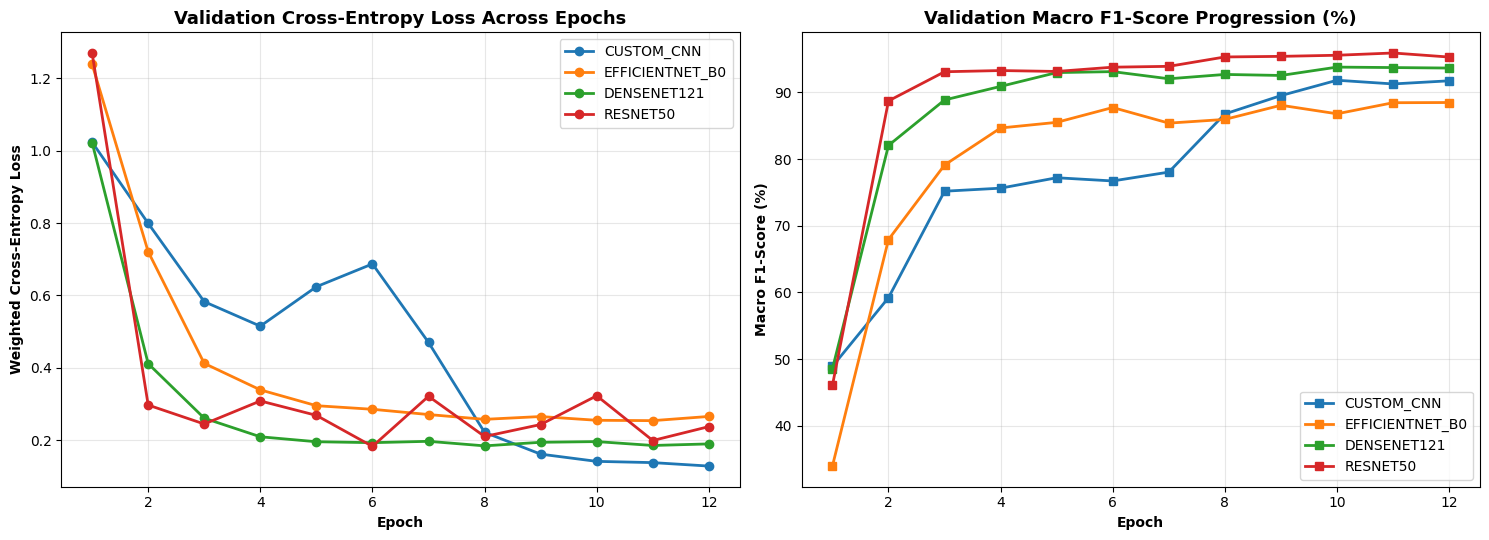

In [ ]:
def plot_convergence_comparison(all_histories):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    for name, hist in all_histories.items():
        epochs_range = range(1, len(hist["val_loss"]) + 1)
        axes[0].plot(epochs_range, hist["val_loss"], marker="o", lw=2, label=name.upper())
        axes[1].plot(epochs_range, [f * 100 for f in hist["val_f1"]], marker="s", lw=2, label=name.upper())

    axes[0].set_title("Validation Cross-Entropy Loss Across Epochs", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Epoch", fontweight="bold")
    axes[0].set_ylabel("Weighted Cross-Entropy Loss", fontweight="bold")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].set_title("Validation Macro F1-Score Progression (%)", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Epoch", fontweight="bold")
    axes[1].set_ylabel("Macro F1-Score (%)", fontweight="bold")
    axes[1].grid(alpha=0.3)
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.savefig("WBC_Convergence_Comparison.png", dpi=300)
    plt.show()

plot_convergence_comparison(all_histories)

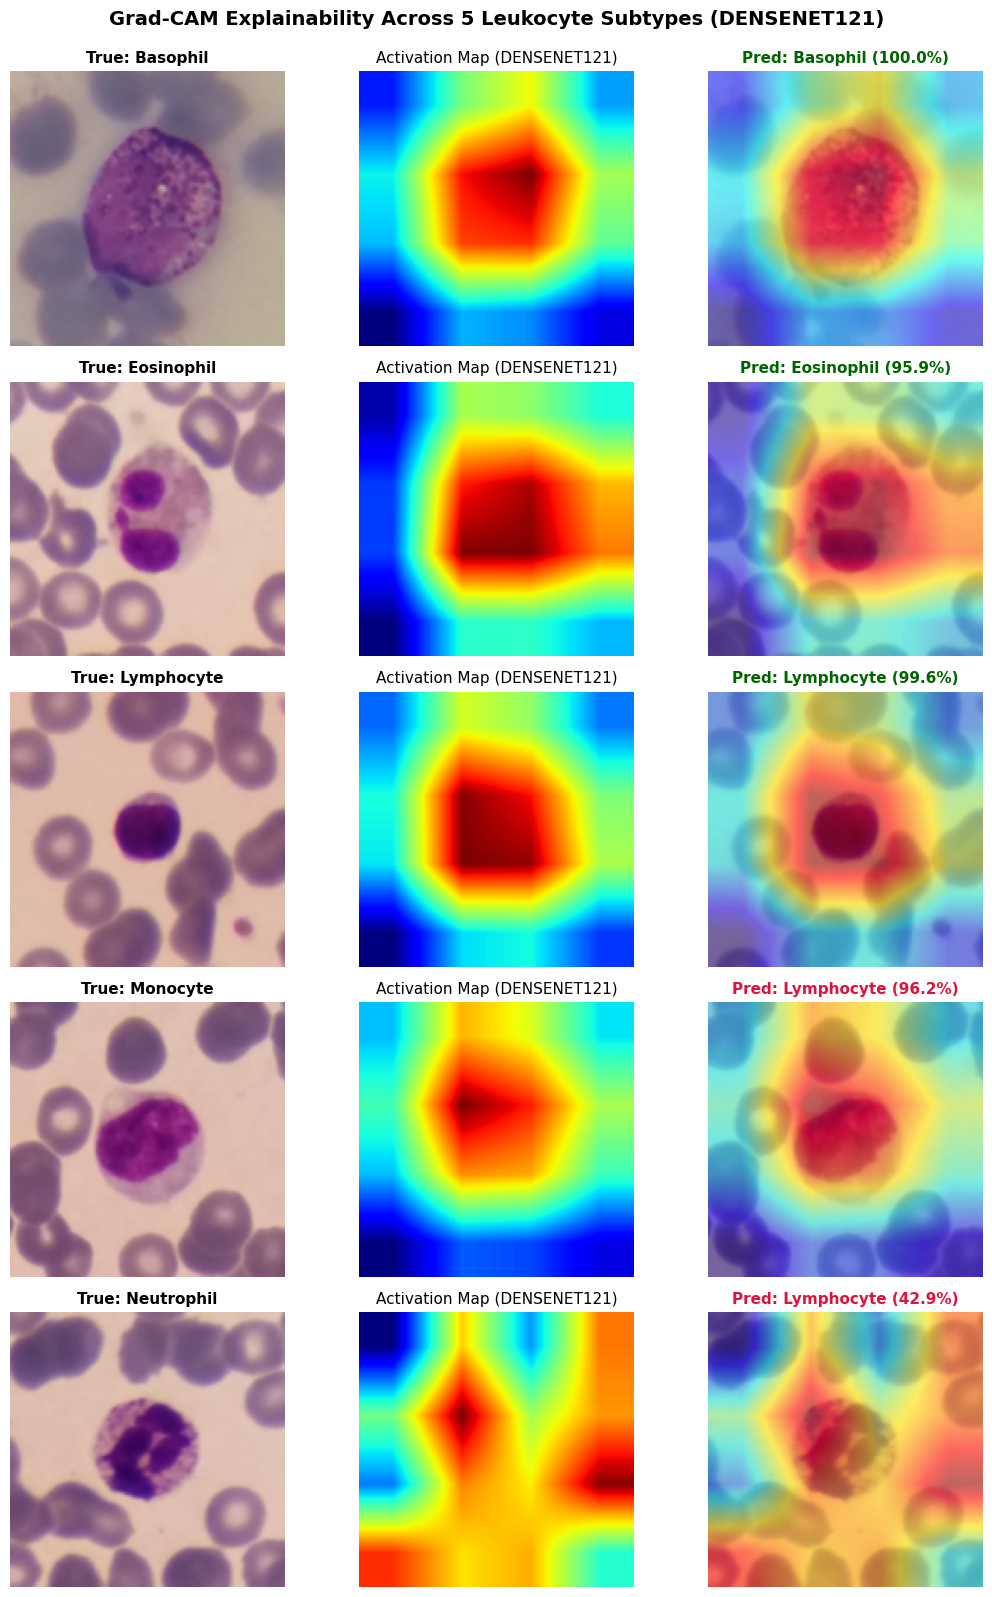

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

def get_target_layer(model, model_name):
    """Returns the last spatial convolutional layer before global pooling."""
    model_name = model_name.lower()
    if model_name == "resnet50":
        return [model.layer4[-1]]
    elif model_name == "densenet121":
        return [model.features.norm5]
    elif model_name == "efficientnet_b0":
        return [model.features[-1]]
    elif model_name == "custom_cnn":
        return [model.features[12]]  # Last Conv2d in Block 4
    else:
        raise ValueError(f"Unknown target layer mapping for {model_name}")

def unnormalize_image(tensor):
    """Converts normalized PyTorch tensor back to [0, 1] RGB numpy array."""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    img = std * img + mean
    return np.clip(img, 0, 1).astype(np.float32)

def generate_gradcam_publication_grid(model, model_name, test_dataset, classes):
    model.eval()
    target_layers = get_target_layer(model, model_name)
    cam = GradCAM(model=model, target_layers=target_layers)

    # Pick 1 sample per WBC class from Test-A
    sample_indices = {}
    for idx in range(len(test_dataset)):
        label = test_dataset.labels[idx].item()
        if label not in sample_indices:
            sample_indices[label] = idx
        if len(sample_indices) == len(classes):
            break

    fig, axes = plt.subplots(len(classes), 3, figsize=(11, 16))

    for row_idx, cls_idx in enumerate(sorted(sample_indices.keys())):
        dataset_idx = sample_indices[cls_idx]
        input_tensor, true_label = test_dataset[dataset_idx]
        input_batch = input_tensor.unsqueeze(0).to(device)

        # Forward pass for prediction confidence
        with torch.no_grad():
            outputs = model(input_batch)
            probs = torch.softmax(outputs, dim=1)
            conf, pred_cls = torch.max(probs, dim=1)
            pred_idx = pred_cls.item()
            confidence = conf.item() * 100

        # Compute Grad-CAM with respect to the predicted class
        targets = [ClassifierOutputTarget(pred_idx)]
        grayscale_cam = cam(input_tensor=input_batch, targets=targets)[0, :]

        rgb_img = unnormalize_image(input_tensor)
        cam_overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        # Column 1: Original Microscopic Smear
        axes[row_idx, 0].imshow(rgb_img)
        axes[row_idx, 0].set_title(f"True: {classes[true_label]}", fontweight="bold", fontsize=11)
        axes[row_idx, 0].axis("off")

        # Column 2: Raw Grad-CAM Attention Heatmap
        axes[row_idx, 1].imshow(grayscale_cam, cmap="jet")
        axes[row_idx, 1].set_title(f"Activation Map ({model_name.upper()})", fontsize=11)
        axes[row_idx, 1].axis("off")

        # Column 3: Grad-CAM Overlay + Prediction Confidence
        axes[row_idx, 2].imshow(cam_overlay)
        axes[row_idx, 2].set_title(
            f"Pred: {classes[pred_idx]} ({confidence:.1f}%)",
            fontweight="bold",
            color="darkgreen" if pred_idx == true_label else "crimson",
            fontsize=11
        )
        axes[row_idx, 2].axis("off")

    plt.suptitle(f"Grad-CAM Explainability Across 5 Leukocyte Subtypes ({model_name.upper()})", fontsize=14, fontweight="bold", y=0.995)
    plt.tight_layout()
    plt.savefig(f"WBC_GradCAM_{model_name}.png", dpi=300)
    plt.show()

# Generate the 5x3 Grad-CAM visual grid for your top-performing model (e.g., DenseNet121 or ResNet50)
generate_gradcam_publication_grid(trained_models["densenet121"], "densenet121", test_dataset, classes)